# Modelling 

**Credit Risk Prediction** (classification of default) : 
1. XGBoost Classification
2. Logistic Regression

In [18]:
import pandas as pd 
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn import metrics
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
import joblib
import shap
from sklearn.metrics import roc_curve
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

In [2]:
df = pd.read_csv('../data/cleaned_lendingclub_important_features.csv')

# Credit Risk Prediction 
First I split the data into 80% for training and 20% for testing. The model learns from the training set, and the test set is kept separate so I can check how it does on loans it has never seen. I used stratify so both sets have the same share of defaults.

In [3]:
#split the data 
X = df.drop(columns=['target_default'])
y = df['target_default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

## Logistic Regression
I started with logistic regression as a baseline. It's a simple model that gives each feature a weight, so it's easy to explain, and it's the classic method banks use for credit scoring. I scaled the features first so they're on a similar range.

In [6]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

logreg = LogisticRegression(random_state=16, max_iter=1000)
logreg.fit(X_train_scaled, y_train)
y_pred = logreg.predict(X_test_scaled)

## Model Evaluation using Confusion Matrix

In [7]:
cnf_matrix = metrics.confusion_matrix(y_test, y_pred)
cnf_matrix

array([[210195,   5492],
       [ 52606,   6409]])

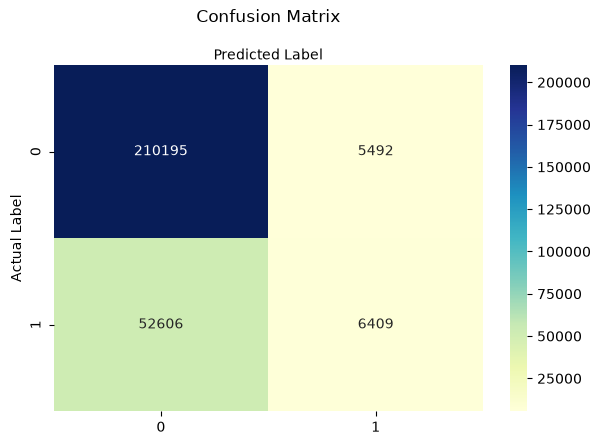

In [8]:
class_names = [0, 1]  # Fully Paid (0), Default (1)
fig, ax = plt.subplots(figsize=(6, 4))
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

sns.heatmap(pd.DataFrame(cnf_matrix), annot=True, fmt='g', cmap="YlGnBu")
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion Matrix', y=1.1)
plt.ylabel('Actual Label')
plt.xlabel('Predicted Label')
plt.show()

In [9]:
# Confusion matrix evaluation using classiifcation_report 
target_names = ['Fully Paid (0)', 'Defaulted (1)']
print(classification_report(y_test, y_pred, target_names=target_names))
accuracy = metrics.accuracy_score(y_test, y_pred)
baseline = 1 - y_test.mean()  # accuracy if we always predict "Fully Paid"
print(f"Accuracy: {accuracy:.1%}  (baseline of always predicting Fully Paid: {baseline:.1%})")

                precision    recall  f1-score   support

Fully Paid (0)       0.80      0.97      0.88    215687
 Defaulted (1)       0.54      0.11      0.18     59015

      accuracy                           0.79    274702
     macro avg       0.67      0.54      0.53    274702
  weighted avg       0.74      0.79      0.73    274702

Accuracy: 78.9%  (baseline of always predicting Fully Paid: 78.5%)


**Why I used AUC instead of accuracy**

Most loans in this data were paid back (about 78%), so if the model just guessed "paid" for everyone, it would already get around 78% accuracy without learning anything. That makes accuracy misleading here.

AUC is better for this because it checks whether the model gives higher risk scores to people who actually defaulted. 0.5 means it's no better than guessing, and 1.0 means perfect.

One thing I noticed is that at the default 0.5 cut-off, the model only catches a small number of defaults. If a bank wanted to catch more of them, it could lower the cut-off, but then more good borrowers would get flagged too.

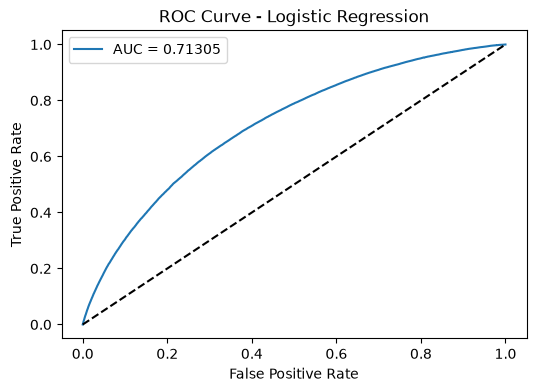

AUC = 0.7130. AUC measures how well the model ranks defaulters above non-defaulters (0.5 = random guessing, 1.0 = perfect).


In [10]:
# ROC AUC Curve
y_proba = logreg.predict_proba(X_test_scaled)[:, 1]  # use the SCALED test data, same as training
roc_auc = roc_auc_score(y_test, y_proba)
roc_auc

fpr, tpr, thresholds = roc_curve(y_test, y_proba)

plt.figure(figsize=(6,4))
plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.5f}")
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Logistic Regression")
plt.legend()
plt.show()

print(f"AUC = {roc_auc:.4f}. AUC measures how well the model ranks defaulters above non-defaulters (0.5 = random guessing, 1.0 = perfect).")


## XGBoost
Next I tried XGBoost, which builds lots of small decision trees where each new tree fixes some of the mistakes from the previous ones. I wanted to see if a more complex model would do much better than the simple baseline.

In [11]:
for col in X.select_dtypes(include='object').columns:
    X[col] = X[col].astype('category')

X_train_xgb, X_test_xgb, y_train_xgb, y_test_xgb = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

In [12]:
dtrain = xgb.DMatrix(X_train_xgb, label=y_train_xgb, enable_categorical=True)
dtest = xgb.DMatrix(X_test_xgb, label=y_test_xgb, enable_categorical=True)

In [13]:
params = {
    "objective": "binary:logistic",   # Binary classification
    "eval_metric": "auc",             # AUC score
    "tree_method": "hist",            # or 'gpu_hist' if using GPU
    "learning_rate": 0.1,
    "max_depth": 4,
}
evals = [(dtrain, "train"), (dtest, "validation")]

model = xgb.train(
    params=params,
    dtrain=dtrain,
    num_boost_round=1000,
    evals=evals,
    early_stopping_rounds=50,
    verbose_eval=10
)

[0]	train-auc:0.69644	validation-auc:0.69475
[10]	train-auc:0.71113	validation-auc:0.70863
[20]	train-auc:0.71665	validation-auc:0.71393
[30]	train-auc:0.72063	validation-auc:0.71766
[40]	train-auc:0.72288	validation-auc:0.71971
[50]	train-auc:0.72434	validation-auc:0.72104
[60]	train-auc:0.72524	validation-auc:0.72180
[70]	train-auc:0.72591	validation-auc:0.72235
[80]	train-auc:0.72636	validation-auc:0.72267
[90]	train-auc:0.72678	validation-auc:0.72294
[100]	train-auc:0.72708	validation-auc:0.72312
[110]	train-auc:0.72734	validation-auc:0.72327
[120]	train-auc:0.72756	validation-auc:0.72340
[130]	train-auc:0.72780	validation-auc:0.72354
[140]	train-auc:0.72799	validation-auc:0.72364
[150]	train-auc:0.72818	validation-auc:0.72373
[160]	train-auc:0.72837	validation-auc:0.72383
[170]	train-auc:0.72856	validation-auc:0.72390
[180]	train-auc:0.72869	validation-auc:0.72395
[190]	train-auc:0.72886	validation-auc:0.72402
[200]	train-auc:0.72900	validation-auc:0.72406
[210]	train-auc:0.72917	

## Model Evaluation

In [14]:
pred_probs_xgb = model.predict(dtest)
auc = roc_auc_score(y_test_xgb, pred_probs_xgb)

print(f"AUC Score: {auc:.4f}")

AUC Score: 0.7248


In [15]:
y_pred_xgb = (pred_probs_xgb > 0.5).astype(int)

print(classification_report(y_test_xgb, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.80      0.97      0.88    269609
           1       0.57      0.12      0.20     73769

    accuracy                           0.79    343378
   macro avg       0.68      0.55      0.54    343378
weighted avg       0.75      0.79      0.73    343378



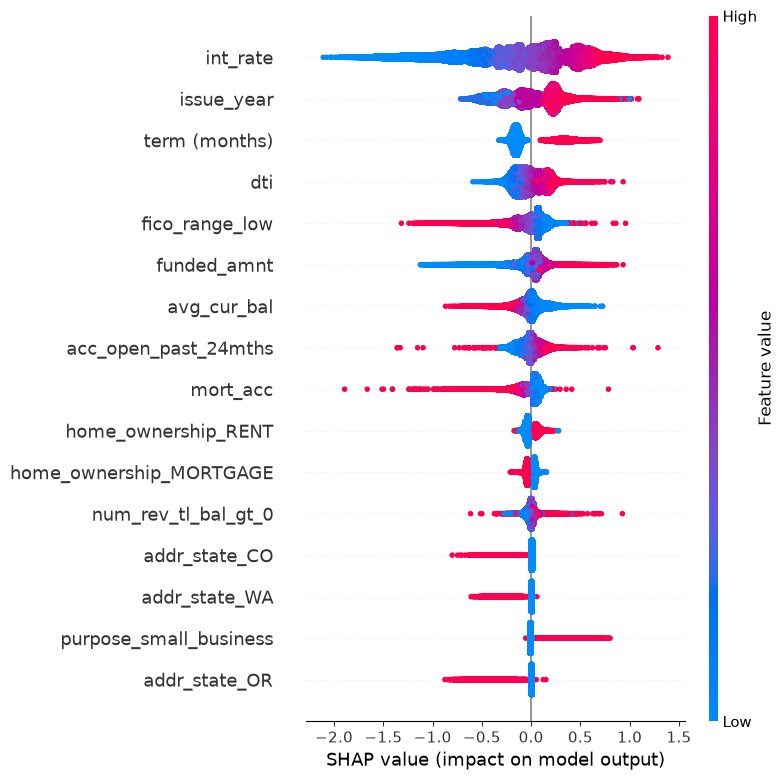

In [16]:
# SHAP to evaluate XGBoost model
explainer = shap.Explainer(model)
shap_values = explainer(dtest)
shap.summary_plot(shap_values, X_test_xgb)


### What SHAP shows

SHAP shows which features push the model toward predicting a default. In the chart, **red** means a **high value** and **blue** means a **low value**, and dots further to the right mean higher risk.

1. **Interest rate** matters the most. High interest rates (red) push the prediction toward default. This makes sense, since riskier borrowers usually get charged higher rates.
2. **Issue year:** more recent loans seem riskier than older ones.
3. **Loan term:** 60-month loans are riskier than 36-month loans, which matches what I found in the EDA.
4. **Debt-to-income ratio:** people who already owe a lot compared to their income are more likely to default.
5. **FICO score** works the other way: a higher credit score (red) pushes the prediction toward paying back.

Other smaller patterns: renters and small-business loans are a bit riskier, while borrowers with higher account balances or more mortgage accounts are a bit safer.

Overall, the model's top features match what I saw in the EDA, which makes me more confident it learned real patterns.

In [17]:
# Save the trained XGBoost model to file
model.save_model('../app/models/xgb_model.json')
joblib.dump(explainer, '../app/models/shap_explainer.pkl')

['../app/models/shap_explainer.pkl']

## Results

- Logistic regression: AUC 0.713
- XGBoost: AUC 0.725

XGBoost did a little better, but not by much. This tells me most of the predicting power comes from a few strong features like interest rate, loan term and debt-to-income, which even the simple model can pick up.

Both models miss a lot of defaults at the 0.5 cut-off. If I kept working on this, I'd try lowering the cut-off or giving the default cases more weight during training, so the model catches more of them.